# 02 | Spectral power, occipital alpha, and connectivity

Analyze retained epochs using channel- and region-level screening, sensitivity analyses for age and response quality, and clinical profile prediction.

**Run in Colab.** See the repository README for Drive access and input paths. Run cells in order and start with notebook 01. Generated files belong in the private working directory. Saved outputs show the original study run.


In [1]:
from pathlib import Path
import os, json, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, rankdata, iqr
from IPython.display import display

if 'EEG_WORK' not in os.environ:
    from google.colab import drive
    drive.mount('/content/drive')
project = Path('/content/drive/MyDrive/پژوهش EEG و میلون — گزارش و نوت‌بوک‌های Colab')
work = Path(os.environ.get('EEG_WORK', project/'ورودی‌های خصوصی بازتحلیل'/'derived'))
cache = Path(os.environ.get('EEG_REFERENCE_DIR', work/'inputs'))
raw_dir = Path(os.environ.get('EEG_RAW', '/content/eeg_mcmi_raw'))
for path in [work,cache,raw_dir]:
    path.mkdir(parents=True,exist_ok=True)
os.chdir(work)
def drive_service():
    from google.colab import auth
    from googleapiclient.discovery import build
    auth.authenticate_user()
    return build('drive','v3',cache_discovery=False)
def read_existing_drive_file(service,file_id,destination):
    from googleapiclient.http import MediaIoBaseDownload
    temp=destination.with_suffix(destination.suffix+'.part')
    with temp.open('wb') as out:
        reader=MediaIoBaseDownload(out,service.files().get_media(fileId=file_id))
        done=False
        while not done:
            _,done=reader.next_chunk()
    temp.replace(destination)
if not (cache/'scores.xlsx').exists():
    original=Path('/content/drive/MyDrive/MCMI_results.xlsx')
    if original.exists():
        shutil.copyfile(original,cache/'scores.xlsx')
    else:
        read_existing_drive_file(drive_service(),'1EOvKbEfvLAQPTjizNE9DEUR9Ik8xBsiy',cache/'scores.xlsx')
scores = pd.read_excel(cache/'scores.xlsx',index_col=0)
assert scores.index.is_unique
manifest=work/'joint/manifest.json'
ids=sorted(s for s in [Path(v[0]).stem for v in json.loads(manifest.read_text())] if scores.loc[s,'سن']>=18) if manifest.exists() else []
channels='Fp1 Fp2 F3 F4 C3 C4 P3 P4 O1 O2 F7 F8 T3 T4 T5 T6 Fz Cz Pz'.split()
def figure(name):
    plt.tight_layout()
    plt.savefig(work/(name+'.png'),dpi=160,bbox_inches='tight')
    plt.show()

Mounted at /content/drive


## Spectral results overview

Each coefficient is a rank correlation across participants. A reliably measured EEG feature may still have a weak relationship with Millon scores.


                  p        q          pmax          half
count  22800.000000  22800.0  22800.000000  22800.000000
mean       0.520462      1.0      0.999952      0.925189
std        0.275543      0.0      0.002170      0.052439
min        0.000600      1.0      0.830008      0.714035
25%        0.288136      1.0      1.000000      0.905263
50%        0.518774      1.0      1.000000      0.938596
75%        0.757662      1.0      1.000000      0.961404
max        1.000000      1.0      1.000000      0.992982


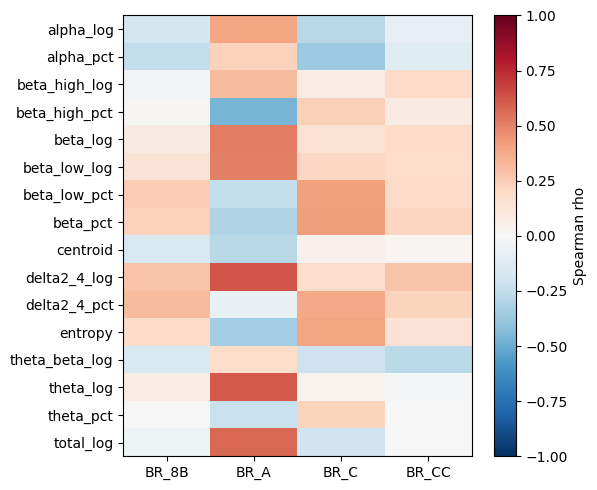

,ویژگی,مقیاس,اسپیرمن,p خام,q,p بیشینه,W کمتر از ۲۰,تعدیل سن
0,اتصال تتا,BR_P,-0.461142,0.050547,0.983391,0.984051,-0.333707,-0.452920
1,اتصال بتا,RAW_2A,-0.448837,0.056447,0.983391,0.991000,-0.387239,-0.448907
2,اتصال آلفا,RAW_6B,-0.447295,0.053047,0.983391,0.991600,-0.502759,-0.449579
3,اتصال بتا,BR_2A,-0.440738,0.060247,0.983391,0.993800,-0.375824,-0.443696
4,اتصال آلفا,BR_6B,-0.422351,0.070696,0.983391,0.998100,-0.459166,-0.422157


In [2]:
for name,file_id in [('EEG_MCMI_Comprehensive_FA.xlsx','1n_Nvm9jxNpSkpXtXucuOW3d2RRgRO86E'),('EEG_MCMI_advanced_FA.xlsx','1mtNEQXJu926-r7f9-VxjJ6tLka6rzh9R')]:
    if not (cache/name).exists():
        read_existing_drive_file(drive_service(),file_id,cache/name)
t=pd.read_excel(cache/'EEG_MCMI_Comprehensive_FA.xlsx',sheet_name=4)
t.columns=['site','feature','score','rho','p','q','pmax','sensitivity','age','half']
print(t[['p','q','pmax','half']].describe())
m=t.query("site=='Parietal' and score in ['BR_8B','BR_C','BR_A','BR_CC']").pivot(index='feature',columns='score',values='rho')
plt.figure(figsize=(6,5));plt.imshow(m,cmap='RdBu_r',vmin=-1,vmax=1,aspect='auto');plt.xticks(range(len(m.columns)),m.columns);plt.yticks(range(len(m)),m.index);plt.colorbar(label='Spearman rho')
figure('02_spectrum')
display(pd.read_excel(cache/'EEG_MCMI_advanced_FA.xlsx',sheet_name=2).head())

## Full analysis across scales

Run notebook 01 in full mode first. Summarize each recording by the median O1/O2 relative alpha measure. Resample participants to estimate confidence intervals.


In [3]:
from scipy.stats import false_discovery_control
rebuild = False  # @param {type:"boolean"}
# Optional full run
if rebuild:
    import numpy as np,pandas as pd, json, base64,io
    from pathlib import Path
    from scipy.signal import periodogram
    from scipy.stats import rankdata,spearmanr
    import matplotlib.pyplot as plt
    j=Path('joint'); d=pd.read_excel(cache/'scores.xlsx').rename(columns={'نام مراجع':'subject','سن':'age'})
    rows=[]
    for name,size in sorted(json.loads((j/'manifest.json').read_text())):
     p=Path('out')/name;assert p.stat().st_size==size
     with np.load(p) as z:
      ix=[list(z['channels']).index(a) for a in ['O1-LE','O2-LE']]
      y=z['eeg'][:,ix].astype(float); f,pw=periodogram(y,fs=int(z['fs']),window='hann',axis=-1)
      rel=100*pw[:,:,(f>=8)&(f<13)].sum(-1)/pw[:,:,(f>=2)&(f<30)].sum(-1)
      per=rel.mean(1);h=len(per)//2
      rows.append([Path(name).stem,np.median(per),np.median(per[:h]),np.median(per[-h:]),2*len(per)])
    t=pd.DataFrame(rows,columns=['subject','alpha','first','second','seconds']).merge(d,on='subject',validate='one_to_one');assert len(t)==20
    a=t[t.age>=18].copy()
    rng=np.random.default_rng(2311)
    def corr(x,y):
     x=x-x.mean(axis=-1,keepdims=True);y=y-y.mean(axis=-1,keepdims=True);return (x*y).sum(-1)/np.sqrt((x*x).sum(-1)*(y*y).sum(-1))
    def test(df,col1,col2):
     x,y=df[[col1,col2]].to_numpy().T;n=len(x);r,s=rankdata(x),rankdata(y);v=corr(r,s)
     idx=rng.integers(n,size=(20000,n));boot=corr(rankdata(x[idx],axis=1),rankdata(y[idx],axis=1));lo,hi=np.nanpercentile(boot,[2.5,97.5])
     sim=corr(r,rng.permuted(np.tile(s,(100000,1)),axis=1));pv=(1+(abs(sim)>=abs(v)-1e-12).sum())/100001
     return [n,v,lo,hi,pv]
    results=[test(a,'first','second'),test(a,'alpha','BR_CC'),test(a[a.W_Score<20],'alpha','BR_CC'),test(a,'alpha','BR_A'),test(a,'alpha','BR_D')]
    loo=[spearmanr(a.drop(i).alpha,a.drop(i).BR_CC).statistic for i in a.index]
    rank=a[['alpha','BR_CC','age']].rank();res=lambda u:u-np.polyval(np.polyfit(rank.age,u,1),rank.age);partial=np.corrcoef(res(rank.alpha),res(rank.BR_CC))[0,1]
    print(results,'loo',min(loo),max(loo),'adjust',partial,'CCZ',spearmanr(a.BR_CC,a.BR_Z).statistic,'W',a.W_Score.value_counts().to_dict(),'Vs',a.V_Score.value_counts().to_dict(),'range',a.alpha.min(),a.alpha.max(), 'age',a.age.agg(['min','max']).to_list(),'BR',a.BR_CC.agg(['min','max']).to_list(), 'meddiff',np.median(abs(a['first']-a['second'])),flush=True)

    names='اسکیزوئید|اجتنابی|افسرده|وابسته|نمایشی|آشفته|خودشیفته|ضداجتماعی|دیگرآزار|جبری|منفی‌گرا|خودآزار|اسکیزوتایپال|مرزی|پارانوئید|اضطراب|علائم جسمی|طیف دوقطبی|افسردگی مداوم|مصرف الکل|مصرف مواد|استرس پس از ضربه|طیف اسکیزوفرنیا|افسردگی اساسی|اختلال هذیانی|افشا|مطلوبیت|منفی‌نمایی'.split('|')
    allrows=[]
    for col in [c for c in a if c.startswith(('BR_','RAW_'))]+['W_Score']:
     n,r,lo,hi,p=test(a,'alpha',col);sub=a[a.W_Score<20];sr=spearmanr(sub.alpha,sub[col]).statistic
     allrows.append([col,r,lo,hi,p,sr])
    table=pd.DataFrame(allrows,columns=['code','r','lo','hi','p','sub'])
    for ix in [table.code.str.startswith('BR'),table.code.str.startswith('RAW'),table.code.eq('W_Score')]:
     table.loc[ix,'q']=false_discovery_control(table.loc[ix,'p']) if ix.sum()>1 else np.nan
    print(table.iloc[:28].sort_values('p').head(8).round(4).to_string(index=False));print(table.iloc[28:].sort_values('p').head(6).round(4).to_string(index=False));print(table.tail(1).round(4));print(a.V_Score.unique())

## Screen of 22,800 associations

Test 400 features across 25 sites or regions against 57 scores. Use 20,000 synchronized permutations, with Benjamini–Hochberg and maximum-statistic corrections.


In [4]:
if rebuild:
    import numpy as np,pandas as pd,json
    from pathlib import Path
    from scipy.stats import rankdata,false_discovery_control,spearmanr
    from scipy.signal import periodogram
    j=Path('joint');d=pd.read_excel(cache/'scores.xlsx').set_index('نام مراجع')
    bands={'delta2_4':(2,4),'theta':(4,8),'alpha':(8,13),'beta_low':(13,20),'beta_high':(20,30),'beta':(13,30)}
    regions={'Frontal':'Fp1 Fp2 F3 F4 F7 F8 Fz','Central':'C3 C4 Cz','Temporal':'T3 T4 T5 T6','Parietal':'P3 P4 Pz','Occipital':'O1 O2'}
    features=[];ids=[];first=[];last=[]
    for name,size in sorted(json.loads((j/'manifest.json').read_text())):
     id=Path(name).stem
     if d.loc[id,'سن']<18:continue
     z=np.load(Path('out')/name);ch=[s.split('-')[0] for s in z['channels']];f,p=periodogram(z['eeg'].astype(float),500,window='hann',axis=-1)
     mask=(f>=2)&(f<30);total=p[:,:,mask].sum(-1)*.5;D={}
     for k,(l,h) in bands.items():
      power=p[:,:,(f>=l)&(f<h)].sum(-1)*.5;D[k+'_log']=np.log10(power);D[k+'_pct']=100*power/total
     D['total_log']=np.log10(total);w=p[:,:,mask]/p[:,:,mask].sum(-1,keepdims=True)
     D['entropy']=-(w*np.log(np.maximum(w,1e-30))).sum(-1)/np.log(w.shape[-1]);D['centroid']=(w*f[mask]).sum(-1);D['theta_beta_log']=D['theta_log']-D['beta_log']
     keys=[];arr=[]
     for area,ix in [(s,[i]) for i,s in enumerate(ch)]+[(s,[ch.index(c) for c in cs.split()]) for s,cs in regions.items()]+[('Global',list(range(19)))]:
      for k,v in D.items():
       keys.append((area,k));arr.append(v[:,ix].mean(1))
     a=np.array(arr);h=a.shape[1]//2;ids.append(id);features.append(np.median(a,1));first.append(np.median(a[:,:h],1));last.append(np.median(a[:,-h:],1))
    X=np.array(features);ds=d.loc[ids];cols=[c for c in ds if c.startswith(('BR_','RAW_'))]+['W_Score'];Y=ds[cols].to_numpy();assert len(ids)==19 and len(keys)==400 and ds.V_Score.nunique()==1
    def norm(x):
     a=rankdata(x,axis=0);a-=a.mean(0);return a/np.sqrt((a*a).sum(0))
    x,y=norm(X),norm(Y);r=x.T@y;counts=np.zeros_like(r);rng=np.random.default_rng(23011);maxs=[]
    for step in range(200):
     perm=np.array([rng.permutation(len(x)) for _ in range(100)]);sim=np.abs(x.T@y[perm]);counts+=(sim>=abs(r)-1e-12).sum(0);maxs.extend(sim.max((1,2)))
    pval=(counts+1)/20001;q=false_discovery_control(pval.ravel()).reshape(r.shape);mx=np.sort(maxs);pf=(1+len(mx)-np.searchsorted(mx,abs(r)-1e-12))/20001
    ok=ds.W_Score.values<20;rs=norm(X[ok]).T@norm(Y[ok]);age=norm(ds[['سن']].to_numpy());xr=x-age@(age.T@x);yr=y-age@(age.T@y);adj=(xr/np.linalg.norm(xr,axis=0)).T@(yr/np.linalg.norm(yr,axis=0));reli=(norm(first)*norm(last)).sum(0)
    out=pd.DataFrame([(a,b,c,r[i,k],pval[i,k],q[i,k],pf[i,k],rs[i,k],adj[i,k],reli[i]) for i,(a,b) in enumerate(keys) for k,c in enumerate(cols)],columns=['site','feature','score','rho','p','q_BH','p_maxT','rho_W14','rho_age','split_half'])
    out.to_pickle('spectral_tests.pkl');pd.DataFrame(X,index=ids,columns=[a+'_'+b for a,b in keys]).to_pickle('spectral_features.pkl')
    for subset in [out,out[out.score.str.startswith('BR')],out[(out.site.isin(regions))&(out.score.str.startswith('BR'))]]:
     print(subset.iloc[np.argmax(abs(subset.rho))].to_dict())
    print('n',len(out),'nominal',(out.p<.05).sum(),'adj',(out.q_BH<.05).sum(),(out.p_maxT<.05).sum(),'rel',np.percentile(reli,[0,50,100]),'qmin',q.min())

## Aperiodic slope, connectivity, and profile prediction

Estimate the spectral slope outside the alpha peak range. Estimate debiased wPLI for channel pairs and assess similarity between the EEG profile and the 25 clinical scores.


In [5]:
if rebuild:
    Path('advanced').mkdir(exist_ok=True)
    import json,numpy as np,pandas as pd
    from pathlib import Path
    from scipy.signal import windows
    from scipy.stats import rankdata,spearmanr,theilslopes,false_discovery_control
    root=Path('advanced'); d=pd.read_excel(cache/'scores.xlsx').set_index('نام مراجع'); records=[];qual=[]
    bands=[(4,8),(8,13),(13,30)];labels=['شیب زمینهٔ پس‌سری','برجستگی آلفای پس‌سری','اتصال تتا','اتصال آلفا','اتصال بتا']
    for name,_ in sorted(json.loads(Path('joint/manifest.json').read_text())):
     sid=Path(name).stem
     if d.loc[sid,'سن']<18:continue
     with np.load(Path('out')/name) as z:
      raw=z['eeg'].astype(float);ch=list(z['channels'])
      ff=np.fft.rfft((raw-raw.mean(-1,keepdims=True))*windows.hann(1000,sym=False),axis=-1)[:,:,:61]
      f=np.arange(61)/2;h=len(ff)//2;i,k=np.triu_indices(19,1)
      def extract(x,upper=25):
       ps=np.log10(np.median((abs(x[:,[ch.index('O1-LE'),ch.index('O2-LE')]])**2).mean(1),axis=0))
       mask=(f>=3)&(f<=upper)&((f<7)|(f>14));am=(f>=8)&(f<13)
       slope,inter,*_=theilslopes(ps[mask],np.log10(f[mask]))
       err=ps[mask]-(inter+slope*np.log10(f[mask]));r2=1-(err@err)/np.sum((ps[mask]-np.mean(ps[mask]))**2)
       alpha=np.mean(ps[am]-inter-slope*np.log10(f[am]))*10
       conn=[]
       for l,u in bands:
        xx=x[:,:,(f>=l)&(f<u)];im=(xx[:,i]*xx[:,k].conj()).imag
        ss=im.sum(0)**2;sq=(im**2).sum(0);den=abs(im).sum(0)**2-sq
        conn.append(np.nanmedian(np.nanmean(np.divide(ss-sq,den,out=np.full_like(sq,np.nan),where=den>0),axis=-1)))
       return [-slope,alpha,*conn],r2,np.median(abs(err))*10
      vals=[]
      for subset,upper in [(ff,25),(ff[:h],25),(ff[-h:],25),(ff[np.linspace(0,len(ff)-1,120,dtype=int)],25),(ff,22)]:
       v,r2,err=extract(subset,upper);vals.append(v)
       if len(vals)==1:qual.append([sid,r2,err])
      records.append((sid,vals))
    ids=[r[0] for r in records];xx=np.array([r[1] for r in records]);ds=d.loc[ids]
    def norm(a):
     t=rankdata(a,axis=0);t-=t.mean(0);return t/np.linalg.norm(t,axis=0)
    def rho(a,b):return norm(a).T@norm(b)
    rel=rho(xx[:,1],xx[:,2]).diagonal();sens=rho(xx[:,0],xx[:,3]).diagonal();freq=rho(xx[:,0],xx[:,4]).diagonal()
    cols=[c for c in d if c.startswith(('BR_','RAW_'))]+['W_Score'];x=norm(xx[:,0]);y=norm(ds[cols].to_numpy());r=x.T@y;rng=np.random.default_rng(410);p=np.zeros_like(r);mt=p.copy(); maxima=[]
    for _ in range(200):
     idx=np.array([rng.permutation(len(x)) for _ in range(100)]);v=abs(x.T@y[idx]);p+=(v>=abs(r)-1e-12).sum(0);maxima.extend(v.max((1,2)))
    p=(1+p)/20001;q=false_discovery_control(p.ravel()).reshape(p.shape);m=(1+20000-np.searchsorted(np.sort(maxima),abs(r)-1e-12))/20001
    sub=ds.W_Score.to_numpy()<20;rs=rho(xx[sub,0],ds[cols].to_numpy()[sub]);age=norm(ds[['سن']].to_numpy());xr=x-age@(age.T@x);yr=y-age@(age.T@y);ra=(xr/np.linalg.norm(xr,axis=0)).T@(yr/np.linalg.norm(yr,axis=0))
    df=pd.DataFrame([(label,c,r[i,k],p[i,k],q[i,k],m[i,k],rs[i,k],ra[i,k]) for i,label in enumerate(labels) for k,c in enumerate(cols)],columns=['ویژگی','مقیاس','اسپیرمن','p خام','q','p بیشینه','W کمتر از ۲۰','تعدیل سن']);df=df.iloc[np.argsort(-abs(df.iloc[:,2].to_numpy()))]
    quality=pd.DataFrame(qual,columns=['شناسه','R2 زمینه','خطای میانه dB']);stability=pd.DataFrame(dict(feature=labels,split=rel,equal120=sens,upper22=freq))
    print(stability.to_string(index=False),quality.describe().to_string(),df.head(5).to_string(index=False),'p<05',sum(p.ravel()<.05),'qmin',q.min(),'r2<.5',sum(quality.iloc[:,1]<.5))
    for i,l in enumerate(labels):
     k=np.argmax(abs(r[i]));print(l,cols[k],r[i,k],p[i,k],m[i,k])
    for name,obj in [('results',df),('stability',stability),('quality',quality),('values',pd.DataFrame(xx[:,0],index=ids,columns=labels))]:obj.to_pickle(root/(name+'.pkl'))

    from pathlib import Path
    import numpy as np,pandas as pd
    from scipy.stats import rankdata
    from scipy.spatial.distance import pdist,squareform
    o=Path('advanced');features=pd.read_pickle(o/'values.pkl');d=pd.read_excel(cache/'scores.xlsx').set_index('نام مراجع').loc[features.index];y=d[[c for c in d if c.startswith('BR_') and c not in ['BR_X','BR_Y','BR_Z']]]
    def centered(a):
     r=rankdata(a,axis=0);r=(r-r.mean(0))/r.std(0);D=squareform(pdist(r));D=D-D.mean(0)-D.mean(1)[:,None]+D.mean();return D/np.linalg.norm(D)
    a,b=centered(features),centered(y);rng=np.random.default_rng(1123);obs=(a*b).sum();sim=[]
    for i in range(100):
     idx=np.array([rng.permutation(len(a)) for _ in range(500)]);sim.extend((a*b[idx[:,:,None],idx[:,None,:]]).sum((1,2)))
    sim=np.asarray(sim);print(np.sqrt(obs),np.median(np.sqrt(sim)),(1+sum(sim>=obs))/(1+len(sim)))